In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### loading data and getting main structure

In [49]:
df = pd.read_csv('GaltonFamilies.csv')
print(df.head())
print(df.columns.tolist())
print(df.shape)
# checking data types
print(df.info())
# checking missing values
print(df.isnull().sum())

   rownames family  father  mother  midparentHeight  children  childNum  \
0         1    001    78.5    67.0            75.43         4         1   
1         2    001    78.5    67.0            75.43         4         2   
2         3    001    78.5    67.0            75.43         4         3   
3         4    001    78.5    67.0            75.43         4         4   
4         5    002    75.5    66.5            73.66         4         1   

   gender  childHeight  
0    male         73.2  
1  female         69.2  
2  female         69.0  
3  female         69.0  
4    male         73.5  
['rownames', 'family', 'father', 'mother', 'midparentHeight', 'children', 'childNum', 'gender', 'childHeight']
(934, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 934 entries, 0 to 933
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   rownames         934 non-null    int64  
 1   family           934 non-null   

### extracting the heights

In [50]:
#  Keep one mother-height observation per family
mothers = (df[['family', 'father']]
           .dropna(subset=['family', 'father'])
           .drop_duplicates(['family', 'father']))
mother_heights = mothers['father'].to_numpy(dtype=float)
child_heights = (df["childHeight"]
    .dropna()
    .to_numpy(dtype=float))
# Putting both populations into one unlabeled dataset
heights = np.concatenate([mother_heights,child_heights])
# verifying data
print("Number of mothers:", len(mother_heights))
print("Number of children:", len(child_heights))
print("Total observations:", len(heights))
print("First 10 pooled heights:", heights[:10])

Number of mothers: 205
Number of children: 934
Total observations: 1139
First 10 pooled heights: [78.5 75.5 75.  75.  75.  74.  74.  74.  74.5 74. ]


### exploring/ understanding data (calculating basic statistics and plot distibution to visualize whether two groups might be mixed together)

Overall mean: 67.20851624231783
Overall variance: 12.724062679938118
Overall standard deviation: 3.567080413999398
Minimum height: 56.0
Maximum height: 79.0


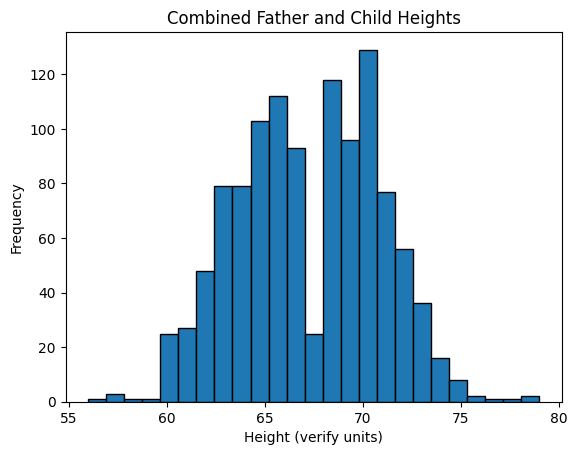

In [51]:
print("Overall mean:", np.mean(heights))
print("Overall variance:", np.var(heights))
print("Overall standard deviation:", np.std(heights))
print("Minimum height:", np.min(heights))
print("Maximum height:", np.max(heights))

plt.hist(heights, bins=25, edgecolor="black")
plt.xlabel("Height (verify units)")
plt.ylabel("Frequency")
plt.title("Combined Father and Child Heights")
plt.show()

#### Looking at the above graph it shows that there are two peaks(one at around 66 and other around 70) which means there are two distinct subgroups. The graph also shows the valley around 68 which indicates that the groups overlaps

## Question: "Should you or should you not simply draw a line at the dataset's global mean to split the data into two piles, and then calculate the mean of each pile?

#### Answer:  No, because the two populations are mixed together in a continuous space, their bell curves overlap significantly, which means shorter parents and taller children fall into the same height range. Drawing a hard line at the global mean creates a hard threshold that forces a data point entirely into one group or another. Instead we will use EM algorithm which calculates the posterior probability of each observation and preserve uncertainty when the distributions overlap.

### Probability density function to determine relative fit or density of each heights (which helps in determining probability of belonging to each component)

In [52]:
def gaussian_pdf(x, mean, variance):
    """
    Calculate the Gaussian probability density
    for each observation in x.
    """
    coefficient = 1 / np.sqrt(2 * np.pi * variance)

    exponent = -((x - mean) ** 2) / (2 * variance)

    return coefficient * np.exp(exponent)

### starting EM algorithm

#### Expectation stage (calculating the probability of belonging to each group for every single piece of data in dataset)

In [53]:
def expectation_step(x, means, variances, mixing):
    """
    Calculate the responsibility of each
    Gaussian component for each observation.
    """
    weighted_densities = np.column_stack([
        mixing[k] * gaussian_pdf(
            x, means[k], variances[k]
        )
        for k in range(2)
    ])

    totals = weighted_densities.sum(axis=1, keepdims=True)

    responsibilities = weighted_densities / totals

    return responsibilities

### Maximisation stage (to update models parameters)



In [54]:
def maximization_step(x, responsibilities):
    """
    Update means, variances and mixing proportions
    using the responsibilities from the E-step.
    """
    n = len(x)

    effective_counts = responsibilities.sum(axis=0)

    means = (
        (responsibilities * x[:, None]).sum(axis=0)
        / effective_counts
    )

    variances = (
        responsibilities * (x[:, None] - means) ** 2
    ).sum(axis=0) / effective_counts

    # Protect against zero or near-zero variance.
    variances = np.maximum(variances, 1e-6)

    mixing = effective_counts / n

    return means, variances, mixing

### calculating log-likelihood (to prove whether the EM algorithm is actually learning)

In [55]:
def calculate_log_likelihood(x, means, variances, mixing):
    """
    Measure how well the model explains
    the observed heights.
    """
    weighted_densities = np.column_stack([
        mixing[k] * gaussian_pdf(
            x, means[k], variances[k]
        )
        for k in range(2)
    ])

    total_density = weighted_densities.sum(axis=1)

    return np.sum(np.log(np.maximum(total_density, 1e-300)))

### all steps together, plus initialisation of guessing

In [56]:
def fit_em(x, max_iterations=500, tolerance=1e-6):
    """
    Fit a two-component Gaussian mixture using
    our own Expectation-Maximization implementation.
    """

    # Initial parameter estimates
    means = np.quantile(x, [0.25, 0.75])

    overall_variance = np.var(x)

    variances = np.array([
        overall_variance,
        overall_variance
    ], dtype=float)

    mixing = np.array([0.5, 0.5])

    history = []

    # Record iteration 0: initialization
    history.append({
        "iteration": 0,
        "means": means.copy(),
        "variances": variances.copy(),
        "mixing": mixing.copy(),
        "log_likelihood": calculate_log_likelihood(
            x, means, variances, mixing
        )
    })

    previous_ll = history[-1]["log_likelihood"]

    for iteration in range(1, max_iterations + 1):

        # E-step: estimate memberships
        responsibilities = expectation_step(
            x, means, variances, mixing
        )

        # M-step: update parameters
        means, variances, mixing = maximization_step(
            x, responsibilities
        )

        # Keep component 1 as the lower-mean component.
        order = np.argsort(means)
        means = means[order]
        variances = variances[order]
        mixing = mixing[order]

        # Measure the updated model
        current_ll = calculate_log_likelihood(
            x, means, variances, mixing
        )

        history.append({
            "iteration": iteration,
            "means": means.copy(),
            "variances": variances.copy(),
            "mixing": mixing.copy(),
            "log_likelihood": current_ll
        })

        # Stop if the log-likelihood barely changes
        if abs(current_ll - previous_ll) < tolerance:
            break

        previous_ll = current_ll

    return means, variances, mixing, history

In [57]:
# Run the EM algorithm
means, variances, mixing, history = fit_em(heights)

# Print the required tracking table
print(
    f"{'Iteration':<12}"
    f"{'μ1 ​(Children)':>12}"
    f"{'μ2​ (Pros)':>12}"
    f"{'σ1²':>12}"
    f"{'σ2²':>12}"
    f"{'π1':>10}"
    f"{'π2':>10}"
    f"{'Log-Likelihood':>20}"
)

for row in history[:3]:
    print(
        f"{row['iteration']:<12}"
        f"{row['means'][0]:>12.4f}"
        f"{row['means'][1]:>12.4f}"
        f"{row['variances'][0]:>12.4f}"
        f"{row['variances'][1]:>12.4f}"
        f"{row['mixing'][0]:>10.4f}"
        f"{row['mixing'][1]:>10.4f}"
        f"{row['log_likelihood']:>20.4f}"
    )

Iteration   μ1 ​(Children)  μ2​ (Pros)         σ1²         σ2²        π1        π2      Log-Likelihood
0                64.5000     70.0000     12.7241     12.7241    0.5000    0.5000          -3119.8222
1                65.2205     69.2054      9.0603      8.4468    0.5011    0.4989          -3057.9135
2                65.1609     69.2600      8.9420      8.1040    0.5005    0.4995          -3056.9719


###test random height

In [59]:
test_height = float(input("Enter a test height: "))

# Calculate the posterior probabilities
posterior = expectation_step(
    np.array([test_height]),
    means,
    variances,
    mixing
)[0]

print(f"\nTest height: {test_height:.2f}")
print(f"Component 1(child) posterior: {posterior[0]:.6%}")
print(f"Component 2(basketball player) posterior: {posterior[1]:.6%}")
print(f"Total probability: {posterior.sum():.6%}")

Enter a test height: 70

Test height: 70.00
Component 1(child) posterior: 3.278444%
Component 2(basketball player) posterior: 96.721556%
Total probability: 100.000000%
